In [1]:
import pandas as pd
import numpy as np
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    average_precision_score,
    roc_auc_score
)

In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()

X_valid = pd.read_csv("../data/processed/X_valid.csv")
y_valid = pd.read_csv("../data/processed/y_valid.csv").squeeze()

preprocessor = joblib.load(
    "../models/preprocessor.joblib"
)

In [3]:
scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=6,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

In [4]:
trained_models = {}
training_results = []

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_valid)

    y_prob = pipeline.predict_proba(X_valid)[:, 1]

    trained_models[name] = pipeline

    training_results.append({
        "Model": name,
        "Precision": precision_score(y_valid, y_pred),
        "Recall": recall_score(y_valid, y_pred),
        "F1": f1_score(y_valid, y_pred),
        "ROC_AUC": roc_auc_score(y_valid, y_prob),
        "PR_AUC": average_precision_score(y_valid, y_prob)
    })

In [5]:
model_results = pd.DataFrame(training_results)

model_results.sort_values(
    by="PR_AUC",
    ascending=False
)

,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.517647,0.823529,0.635707,0.859394,0.678084
3,XGBoost,0.536449,0.767380,0.631463,0.848693,0.670740
2,Random Forest,0.596059,0.647059,0.620513,0.835720,0.620122
1,Decision Tree,0.523191,0.754011,0.617744,0.824917,0.605412


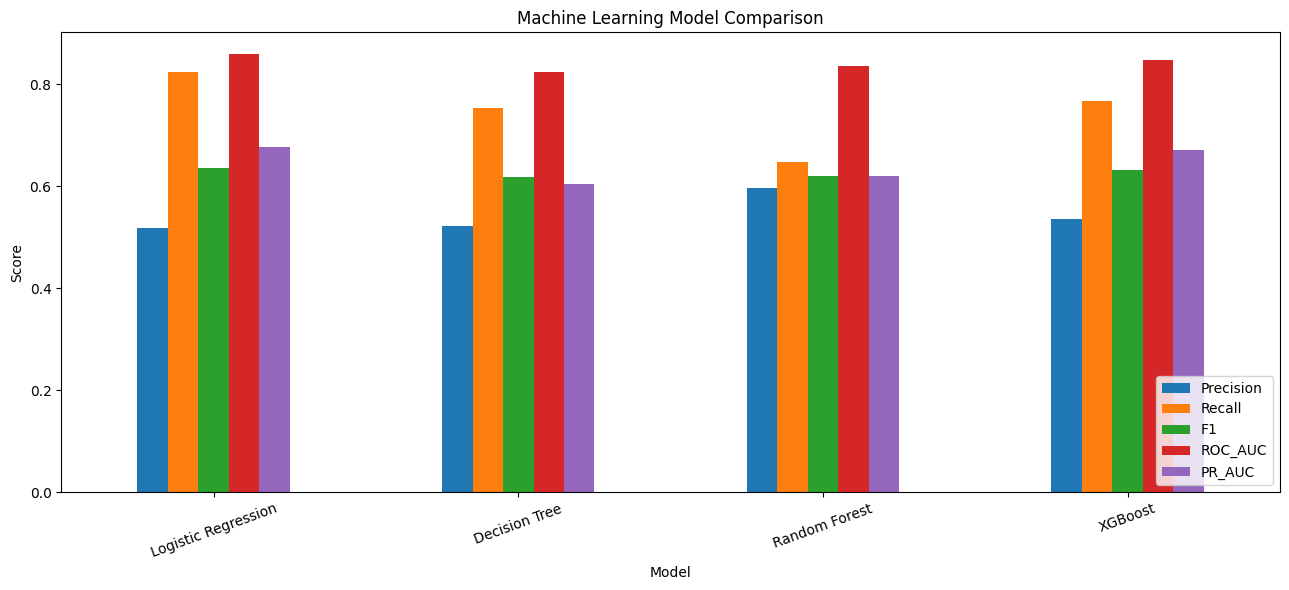

In [7]:
import matplotlib.pyplot as plt

model_results.set_index("Model")[
    ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [8]:
from pathlib import Path

Path("../models").mkdir(exist_ok=True)

for name, model in trained_models.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        + ".joblib"
    )

    joblib.dump(
        model,
        f"../models/{filename}"
    )